# Задача A

In [1]:
%time
# n = int(input())
# cards = input().split()
n = int("5")
cards = "1 3 2 4 4".split()
# n = int("6")
# cards = "1 7 2 9 11 15".split()
# count = [0 for i in range(n-1)]
# count = []
# indxs = []
# for i, card_to_match in enumerate(cards):
#     # for card in cards[i+1:]:
#         # print(cards[i:])
#         # if card != card_to_match:
#         #     count[i] += 1
#         # else:
#             # break
#     # print(cards[i+1:])
#     if card_to_match in cards[i+1:]:
#         indxs.append(cards[i+1:].index(card_to_match))
#     else:
#         indxs.append(-1)
indxs = [
    cards[i+1:].index(card_to_match)
    for i, card_to_match in enumerate(cards) if card_to_match in cards[i+1:]
]
# print(indxs)
# valid_indxs = [index for index in indxs if (index > -1)]
if len(indxs) != 0:
    print(min(indxs))
else:
    print(-1)

CPU times: user 1e+03 ns, sys: 0 ns, total: 1e+03 ns
Wall time: 2.86 μs
0


# Задача E

In [1]:
import csv
import keras
from keras import layers
import numpy as np
import matplotlib.pyplot as plt


2025-02-21 17:23:46.492955: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-02-21 17:23:46.493013: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-02-21 17:23:46.494131: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-02-21 17:23:46.498709: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
with open("data/train.csv", mode="r", encoding="utf-8") as csvfile:
    reader = csv.DictReader(csvfile)
    read_data = np.array(
        [(row["word_name"], row["class_name"]) for row in reader]
    )
np.random.shuffle(read_data)
test_data_size = len(read_data) // 4
test_data = [row[0] for row in read_data[:test_data_size]]
test_labels = [row[1] for row in read_data[:test_data_size]]
train_data = [row[0] for row in read_data[test_data_size:]]
train_labels = [row[1] for row in read_data[test_data_size:]]


In [3]:
# alphabet = "abcdefghijklmnopqrstuvwxyz"
# alphabet_dict = {letter: i for i, letter in enumerate(alphabet)}


# def vectorize_word(word, word_length=32):
#     vectorized_word = [[0 for _ in range(26)] for _ in range(word_length)]
#     for i, letter in enumerate(word):
#         vectorized_word[i][alphabet_dict[letter]] = 1
#     return vectorized_word

# train_data_vectorized = np.array(
#     [vectorize_word(word) for word in train_data]
# ).reshape(len(train_data), 32*26)
# train_labels_vectorized = np.array([0 for label in train_labels])
# for i, label in enumerate(train_labels):
#     if label == "A":
#         train_labels_vectorized[i] = 1
# test_data_vectorized = np.array(
#     [vectorize_word(word) for word in test_data]
# ).reshape(len(test_data), 32*26)
# test_labels_vectorized = np.array([0 for label in test_labels])
# for i, label in enumerate(test_labels):
#     if label == "A":
#         test_labels_vectorized[i] = 1


In [4]:
alphabet = "abcdefghijklmnopqrstuvwxyz"
alphabet_dict = {letter: i for i, letter in enumerate(alphabet)}


def vectorize_words(words, word_length=32):
    vectorized_words = np.zeros((len(words), word_length, 26))
    for i, word in enumerate(words):
        for j, letter in enumerate(word):
            vectorized_words[i, j, alphabet_dict[letter]] = 1
    # vectorized_words.reshape(len(words), word_length*26)
    return vectorized_words.reshape(len(words), word_length*26)

def vectorize_labels(labels):
    vectorized_labels = np.zeros(len(labels))
    for i, label in enumerate(labels):
        if label == "A":
            vectorized_labels[i] = 1
    return vectorized_labels


train_data_vectorized = vectorize_words(train_data)
train_labels_vectorized = vectorize_labels(train_labels)
test_data_vectorized = vectorize_words(test_data)
test_labels_vectorized = vectorize_labels(test_labels)

In [11]:
def build_model():
    model = keras.Sequential([layers.Dense(16, activation="relu"),
                              layers.Dense(16, activation="relu"),
                              layers.Dense(1, activation="sigmoid")])
    model.compile(optimizer="rmsprop", loss="binary_crossentropy", metrics=["accuracy"])
    return model


k = 5
num_of_val_samples = len(train_data_vectorized) // k
num_of_epochs = 500
# training_losses = []
validation_losses = []
validation_accuracies = []
for i in range(k):
    print(f"Processing fold #{i+1} out of {k}...")
    val_data = train_data_vectorized[i*num_of_val_samples:(i+1)*num_of_val_samples]
    val_targets = train_labels_vectorized[i*num_of_val_samples:(i+1)*num_of_val_samples]
    # print(train_data_vectorized[:i*num_of_val_samples])
    train_data_partial = np.concatenate(
        [
            train_data_vectorized[:i*num_of_val_samples],
            train_data_vectorized[(i+1)*num_of_val_samples:]
        ]
    )
    train_labels_partial = np.concatenate(
        [
            train_labels_vectorized[:i*num_of_val_samples],
            train_labels_vectorized[(i+1)*num_of_val_samples:]
        ]
    )
    # print(train_labels_partial)
    model = build_model()
    history = model.fit(train_data_partial,
                        train_labels_partial,
                        epochs=num_of_epochs,
                        batch_size=1024,
                        validation_data=(val_data, val_targets),
                        verbose=0)
    # training_loss_history = history.history["loss"]
    validation_loss_history = history.history["val_loss"]
    # training_losses.append(training_loss_history)
    validation_accuracy_history = history.history["val_accuracy"]
    validation_losses.append(validation_loss_history)
    validation_accuracies.append(validation_accuracy_history)
print("Done.")


Processing fold #1 out of 5...
Processing fold #2 out of 5...
Processing fold #3 out of 5...
Processing fold #4 out of 5...
Processing fold #5 out of 5...
Done.


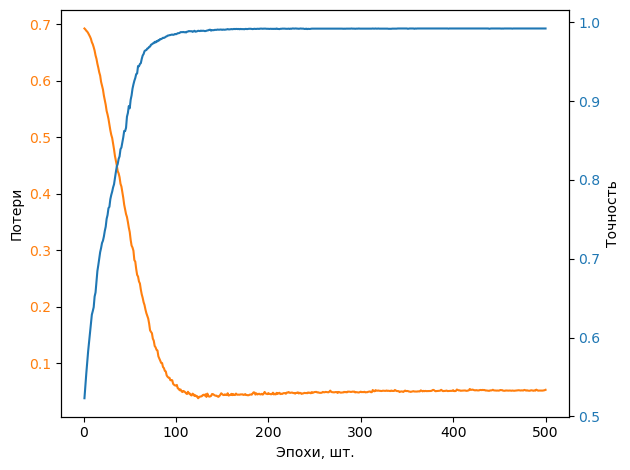

In [12]:
# trainig_losses_average = [
#     np.mean([l[i] for l in training_losses]) for i in range(num_of_epochs)
# ]
validation_losses_average = [
    np.mean([l[i] for l in validation_losses]) for i in range(num_of_epochs)
]
validation_accuracies_average = [
    np.mean([l[i] for l in validation_accuracies]) for i in range(num_of_epochs)
]
fig, ax1 = plt.subplots()
color = "tab:orange"
ax1.plot(range(1, num_of_epochs+1), validation_losses_average, color=color)
ax1.set_xlabel("Эпохи, шт.")
ax1.set_ylabel("Потери")
ax1.tick_params(axis="y", labelcolor=color)
ax2 = ax1.twinx()
color = "tab:blue"
ax2.plot(range(1, num_of_epochs+1), validation_accuracies_average, color=color)
ax2.set_ylabel("Точность")
ax2.tick_params(axis="y", labelcolor=color)
fig.tight_layout()
plt.show()

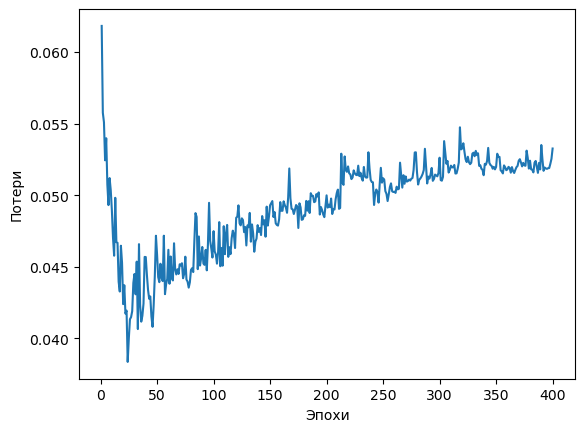

In [13]:
# training_losses_truncated = trainig_losses_average[10:]
validation_losses_truncated =validation_losses_average[100:]
# plt.plot(range(1, len(training_losses_truncated)+1),
#          training_losses_truncated,
#          label="Потери на этапе обучения")
plt.plot(range(1, len(validation_losses_truncated)+1), validation_losses_truncated)
         # label="Потери на этапе проверки")
plt.xlabel("Эпохи")
plt.ylabel("Потери")
# plt.legend()
plt.show()


In [14]:
oferfitting_epoch = validation_losses_average.index(
    min(validation_losses_average)
)
oferfitting_epoch


123

In [15]:
new_model = build_model()
print("Fitting model...")
new_model.fit(train_data_vectorized,
              train_labels_vectorized,
              epochs=125,
              batch_size=1024,
              verbose=0)
print("Fitting comlete.")
# print("Evaluationg model...")
results = new_model.evaluate(test_data_vectorized,
                             test_labels_vectorized,
                             verbose=0)
print(f"Потери на контрольной выборке: {(results[0]):.4f}")
print(f"Точность на контрольной выборке: {(results[1]):.4f}")


Fitting model...
Fitting comlete.
Потери на контрольной выборке: 0.0776
Точность на контрольной выборке: 0.9873


In [19]:
with open("data/test.csv", mode="r", encoding="utf-8") as csvfile:
    reader = csv.DictReader(csvfile)
    data_to_predict = [row["word_name"] for row in reader]
# data_to_predict_vectorized = np.array(
#     [vectorize_word(word) for word in data_to_process]
# ).reshape(len(data_to_process), 32*26)
data_to_predict_vectorized = vectorize_words(data_to_predict)
predictions_vectorized = new_model.predict(data_to_predict_vectorized,
                                           verbose=0)


In [20]:
predictions = []
for prediction in predictions_vectorized:
    if prediction > 0.5:
        predictions.append("A")
    elif prediction < 0.5:
        predictions.append("B")


In [21]:
with open("data/result.csv", mode="w", encoding="utf-8", newline='') as csvfile:
    writer = csv.DictWriter(csvfile, fieldnames=["word_name", "class_name"])
    writer.writeheader()
    for i in range(len(data_to_predict)):
        writer.writerow({"word_name": data_to_predict[i], "class_name": predictions[i]})
    

# Задача F

In [30]:
# n = int(input())
# t1, t2, k = [int(el) for el in input().split()]
# mtrx = [[int(el) for el in input().split()] for i in range(n)]
n = 5
t1, t2, k = 1, 2, 3
mtrx = [[0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 5, 0, 0],
        [0, 1, 0, 1, 0],
        [0, 0, 0, 0, 0]]
########################################
def count_neigbors(point):
    result = sum([1
                  for j in range(point[1]-1, point[1]+2)
                  for i in range(point[0]-1, point[0]+2)
                  if (mtrx[i][j] >= t1) and ((i, j) != point)])
    return result

def find_neigbors(point, exceptions=[]):
    exceptions.append(point)
    result = [(i, j)
              for j in range(point[1]-1, point[1]+2)
              for i in range(point[0]-1, point[0]+2)
              if (mtrx[i][j] >= t1) and (i, j) not in exceptions]
    return result


heavy = [(i, j) for j in range(n) for i in range(n) if mtrx[i][j] >= t2]
find_neigbors(heavy[0])

[(3, 1), (3, 3)]